# TD2 — Corrigé

Boucles, conditions et proportions avec données OWID

Le Brésil ajouté à l’exercice 4 reste présent : neuf observations sont utilisées ensuite. La ligne World est conservée pour suivre l’énoncé, mais elle représente un agrégat mondial, pas un pays supplémentaire. Les proportions sont celles des lignes de cet extrait.

Exécuter toutes les cellules dans l’ordre, depuis une session neuve. Pour les données, extraire le dossier complet et ouvrir le notebook à sa racine. Les sorties sont celles d’une exécution de référence.

Bibliothèques : matplotlib ; pandas en plus au TD5.

In [1]:
# Afficher les figures dans le notebook.
%matplotlib inline

## Démarche en pseudo-code 1 — Classer des observations

```text
# Objectif : classer des pays selon un indicateur
# Entree : liste de pays et valeurs de CO2 par habitant
# Pour chaque pays :
#     lire la valeur
#     comparer la valeur a un seuil
#     afficher une categorie
# Compter combien de pays sont dans chaque categorie
# Sortie : effectifs, proportions, interpretation
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Démarche en pseudo-code 2 — Préparer des listes pour un graphique

```text
# Objectif : tracer une valeur par pays
# Entree : liste de dictionnaires
# 1. Creer une liste vide pour les noms de pays
# 2. Creer une liste vide pour les valeurs de CO2
# 3. Parcourir les observations une par une
# 4. Ajouter le pays et la valeur dans les deux listes
# 5. Tracer puis sauvegarder un graphique
# Sortie : figure png
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Exercice 1 — Observer un dictionnaire seul

**Objectif.** Lire et modifier une observation.

**Démarche.** Les clés sont les noms des informations. Les crochets permettent de lire la valeur correspondant à une clé.

In [2]:
obs = {"pays": "France", "co2_pc": 4.7}
print(obs["pays"])
print(obs["co2_pc"])
obs["co2_pc"] = 5.1
print(obs["pays"])
print(obs["co2_pc"])


France
4.7
France
5.1


**Résultat et interprétation.** Avant modification : France, 4.7 ; après : France, 5.1. Le nom du pays est conservé.

## Exercice 2 — Identifier une clé de dictionnaire

**Objectif.** Identifier une clé absente.

**Démarche.** Le dictionnaire de cet exercice est recréé avec 4.7. La clé population n’existe pas : remplacer cette clé par co2_pc.

In [3]:
obs = {"pays": "France", "co2_pc": 4.7}
print(obs["pays"])
# print(obs["population"]) provoquerait KeyError: 'population'.
print(obs["co2_pc"])


France
4.7


**Résultat et interprétation.** France puis 4.7. Les guillemets et l’orthographe exacte des clés comptent.

## Exercice 3 — Créer une liste de dictionnaires

**Objectif.** Créer les huit observations initiales.

**Démarche.** Chaque dictionnaire réunit un nom et une valeur ; la liste rassemble ces observations dans un ordre donné.

In [4]:
donnees = [
    {"pays": "France", "co2_pc": 4.7},
    {"pays": "Germany", "co2_pc": 7.9},
    {"pays": "Spain", "co2_pc": 5.0},
    {"pays": "Poland", "co2_pc": 8.4},
    {"pays": "United States", "co2_pc": 14.9},
    {"pays": "India", "co2_pc": 2.0},
    {"pays": "China", "co2_pc": 8.0},
    {"pays": "World", "co2_pc": 4.7}
]
print("Nombre d'observations :", len(donnees))
print("Première observation :", donnees[0])


Nombre d'observations : 8
Première observation : {'pays': 'France', 'co2_pc': 4.7}


**Résultat et interprétation.** 8 observations ; le premier dictionnaire correspond à France, 4.7.

## Exercice 4 — Ajouter une observation courte

**Objectif.** Ajouter le Brésil.

**Démarche.** append ajoute le dictionnaire à la fin. La boucle parcourra automatiquement cette nouvelle ligne.

In [5]:
donnees.append({"pays": "Brazil", "co2_pc": 2.3})
print(len(donnees))
print(donnees[-1])


9
{'pays': 'Brazil', 'co2_pc': 2.3}


**Résultat et interprétation.** 9 ; {'pays': 'Brazil', 'co2_pc': 2.3}.

## Exercice 5 — Parcourir les observations

**Objectif.** Afficher une phrase par observation.

**Démarche.** À chaque tour de boucle, obs représente un dictionnaire différent. Le code indenté est répété pour toutes les lignes.

In [6]:
for obs in donnees:
    print(f"{obs['pays']} : {obs['co2_pc']:.1f} tonnes par habitant")


France : 4.7 tonnes par habitant
Germany : 7.9 tonnes par habitant
Spain : 5.0 tonnes par habitant
Poland : 8.4 tonnes par habitant
United States : 14.9 tonnes par habitant
India : 2.0 tonnes par habitant
China : 8.0 tonnes par habitant
World : 4.7 tonnes par habitant
Brazil : 2.3 tonnes par habitant


**Résultat et interprétation.** Neuf phrases, de France : 4.7 à Brazil : 2.3 tonnes par habitant.

## Exercice 6 — Classer avec une condition

**Objectif.** Classer les observations selon les trois catégories.

**Démarche.** Tester d’abord le seuil inférieur. Le elif est examiné seulement si la première condition est fausse : à ce stade la valeur est déjà au moins égale à 5.

In [7]:
for obs in donnees:
    pays = obs["pays"]
    co2 = obs["co2_pc"]
    if co2 < 5:
        categorie = "faible"
    elif co2 < 10:
        categorie = "intermediaire"
    else:
        categorie = "eleve"
    print(pays, categorie)


France faible
Germany intermediaire
Spain intermediaire
Poland intermediaire
United States eleve
India faible
China intermediaire
World faible
Brazil faible


**Résultat et interprétation.** faible : France, India, World, Brazil ; intermediaire : Germany, Spain, Poland, China ; eleve : United States.

## Exercice 7 — Tester les seuils avant la boucle complète

**Objectif.** Vérifier les valeurs exactement aux seuils.

**Démarche.** Réutiliser les mêmes conditions sur quatre valeurs tests, indépendamment des données.

In [8]:
# Attendus : faible, intermediaire, intermediaire, eleve.
for valeur in [4.9, 5.0, 9.9, 10.0]:
    if valeur < 5:
        categorie = "faible"
    elif valeur < 10:
        categorie = "intermediaire"
    else:
        categorie = "eleve"
    print(valeur, categorie)
# 5.0 n'est pas strictement inférieur à 5 : il est intermédiaire.


4.9 faible
5.0 intermediaire
9.9 intermediaire
10.0 eleve


**Résultat et interprétation.** 4.9 faible ; 5.0 intermediaire ; 9.9 intermediaire ; 10.0 eleve.

## Exercice 8 — Compter une proportion

**Objectif.** Compter les valeurs strictement supérieures à 5.

**Démarche.** Initialiser le compteur avant la boucle. Ajouter 1 seulement lorsque la condition est vraie, puis diviser par le nombre total de lignes.

In [9]:
compteur = 0
for obs in donnees:
    if obs["co2_pc"] > 5:
        compteur = compteur + 1
proportion = compteur / len(donnees) * 100
print("Effectif au-dessus de 5 :", compteur)
print(f"{proportion:.1f} % des observations sont au-dessus du seuil.")


Effectif au-dessus de 5 : 4
44.4 % des observations sont au-dessus du seuil.


**Résultat et interprétation.** 4 sur 9, soit 44.4 %. Spain vaut exactement 5 et n’est pas comptée. Avant ajout du Brésil, on aurait 4 sur 8 = 50.0 %.

**Point de vigilance.** Le 62.5 % de l’énoncé illustre une forme de phrase ; il ne correspond pas à ces données. Ne pas confondre le test > 5 avec la catégorie intermédiaire, qui inclut 5.

## Exercice 9 — Graphique des émissions par habitant

**Objectif.** Préparer puis tracer deux listes alignées.

**Démarche.** Partir de deux listes vides. À chaque tour de boucle, ajouter le nom et sa valeur ensemble.

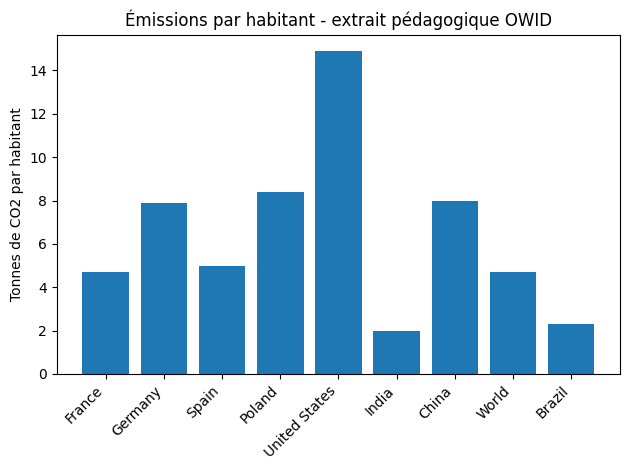

In [10]:
import matplotlib.pyplot as plt

noms_pays = []
valeurs_co2 = []
for obs in donnees:
    noms_pays.append(obs["pays"])
    valeurs_co2.append(obs["co2_pc"])
plt.figure()
plt.bar(noms_pays, valeurs_co2)
plt.ylabel("Tonnes de CO2 par habitant")
plt.title("Émissions par habitant - extrait pédagogique OWID")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("co2_td2.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Neuf barres ; United States est la plus haute. La barre World est une référence agrégée et non un pays.

## Exercice 10 — Créer une fonction de classement

**Objectif.** Écrire une fonction réutilisable de classement.

**Démarche.** valeur est le paramètre. return renvoie la catégorie à l’endroit de l’appel ; print sert ensuite à l’afficher.

In [11]:
def classe_co2(valeur):
    if valeur < 5:
        return "faible"
    elif valeur < 10:
        return "intermediaire"
    else:
        return "eleve"

print(classe_co2(4.7))
print(classe_co2(7.9))
print(classe_co2(14.9))
for obs in donnees:
    print(obs["pays"], classe_co2(obs["co2_pc"]))


faible
intermediaire
eleve
France faible
Germany intermediaire
Spain intermediaire
Poland intermediaire
United States eleve
India faible
China intermediaire
World faible
Brazil faible


**Résultat et interprétation.** Les trois tests renvoient faible, intermediaire, eleve. La boucle retrouve le classement de l’exercice 6.

## Exercice 11 — Débogage : boucle, compteur, indentation

**Objectif.** Corriger indentation et initialisation du compteur.

**Démarche.** Le corps de for est indenté une fois ; le corps du if imbriqué est indenté une seconde fois. Un compteur doit exister avant d’être incrémenté.

In [12]:
# A : sans indentation après for, Python signale IndentationError.
for obs in donnees:
    print(obs["pays"])

# B : dans une session neuve, compteur inconnu provoque NameError.
# S'il existe déjà, ce fragment peut modifier une ancienne valeur par erreur.
compteur = 0
compteur = compteur + 1
print("Compteur après une augmentation :", compteur)

# C : la ligne après if doit être à l'intérieur de la condition.
compteur = 0
for obs in donnees:
    if obs["co2_pc"] > 5:
        compteur = compteur + 1
print("Compteur corrigé :", compteur)


France
Germany
Spain
Poland
United States
India
China
World
Brazil
Compteur après une augmentation : 1
Compteur corrigé : 4


**Résultat et interprétation.** A affiche les neuf noms ; B affiche 1 ; C compte 4 observations. Relancer dans une session neuve évite qu’un ancien compteur masque une erreur.

## Exercice 12 — Question économique

**Objectif.** Répondre aux quatre questions économiques.

**Démarche.** Lire le maximum du graphique, comparer les valeurs françaises et mondiales, puis utiliser le bon dénominateur.

In [13]:
# United States a la valeur la plus élevée : 14,9 tonnes par habitant.
# France et World sont à égalité dans cet extrait arrondi : 4,7.
# Quatre des neuf lignes dépassent 5 tonnes : 44,4 %.
# Les émissions par habitant sont rapportées à la population ; un pays
# très peuplé peut avoir un total élevé sans la plus forte valeur par habitant.


**Résultat et interprétation.** La France n’est ni au-dessus ni au-dessous : elle est égale à la référence mondiale arrondie. En excluant World, la proportion de pays serait 4/8 = 50 %.

## Exercice 13 — Contrôle final

**Objectif.** Contrôler le script complet.

**Démarche.** Vérifier la présence de chaque notion et exécuter les exercices dans l’ordre.

In [14]:
# Liste de dictionnaires : exercice 3 ; boucle : 5 ; conditions : 6.
# Compteur et proportion : 8 ; graphique : 9 ; fonction : 10.
# Interprétation : exercice 12.
print("Contrôle final : TD2 terminé, figure co2_td2.png enregistrée.")


Contrôle final : TD2 terminé, figure co2_td2.png enregistrée.


**Résultat et interprétation.** Le parcours obligatoire produit une figure et une proportion de 44.4 %.

## Question facultative 1 — Recalculer avec un seuil de 7.

**Objectif.** Recalculer avec un seuil de 7.

**Démarche.** Repartir d’un compteur nul et conserver les neuf observations.

In [15]:
compteur_7 = 0
for obs in donnees:
    if obs["co2_pc"] > 7:
        compteur_7 = compteur_7 + 1
print(f"Au-dessus de 7 : {compteur_7 / len(donnees) * 100:.1f} %")


Au-dessus de 7 : 44.4 %


**Résultat et interprétation.** 4/9 = 44.4 %. Aucune valeur de l’extrait n’est strictement entre 5 et 7.

## Question facultative 2 — Lister les pays classés eleve.

**Objectif.** Lister les pays classés eleve.

**Démarche.** Ajouter un nom seulement si la fonction renvoie la catégorie recherchée.

In [16]:
pays_eleves = []
for obs in donnees:
    if classe_co2(obs["co2_pc"]) == "eleve":
        pays_eleves.append(obs["pays"])
print(pays_eleves)


['United States']


**Résultat et interprétation.** ['United States'].

## Question facultative 3 — Calculer une moyenne sans sum.

**Objectif.** Calculer une moyenne sans sum.

**Démarche.** Un accumulateur reçoit la somme au fil de la boucle ; la division se fait après les neuf additions.

In [17]:
total_co2 = 0
for obs in donnees:
    total_co2 = total_co2 + obs["co2_pc"]
print(f"Moyenne simple : {total_co2 / len(donnees):.2f} tonnes par habitant")


Moyenne simple : 6.43 tonnes par habitant


**Résultat et interprétation.** 6.43 tonnes par habitant. Cette moyenne de lignes, contenant World, ne mesure pas les émissions mondiales par habitant.

## Question facultative 4 — Vérifier l’ajout d’un pays sans inventer sa valeur.

**Objectif.** Vérifier l’ajout d’un pays sans inventer sa valeur.

**Démarche.** Le Brésil est l’ajout fourni par l’énoncé. Reconstituer les huit lignes de départ sur une copie puis l’ajouter, sans modifier donnees.

In [18]:
donnees_test = donnees[:-1]  # Copie sans le Brésil ajouté à l'exercice 4.
donnees_test.append({"pays": "Brazil", "co2_pc": 2.3})
for obs in donnees_test:
    print(obs["pays"], classe_co2(obs["co2_pc"]))
print("Nombre de lignes après ajout :", len(donnees_test))


France faible
Germany intermediaire
Spain intermediaire
Poland intermediaire
United States eleve
India faible
China intermediaire
World faible
Brazil faible
Nombre de lignes après ajout : 9


**Résultat et interprétation.** Le Brésil est classé faible et les neuf lignes sont parcourues.

## Question facultative 5 — Afficher les pays sous la référence mondiale.

**Objectif.** Afficher les pays sous la référence mondiale.

**Démarche.** Rechercher d’abord la ligne World, puis comparer chaque ligne à sa valeur.

In [19]:
for obs in donnees:
    if obs["pays"] == "World":
        valeur_mondiale = obs["co2_pc"]
for obs in donnees:
    if obs["co2_pc"] < valeur_mondiale:
        print(obs["pays"])


India
Brazil


**Résultat et interprétation.** India et Brazil. France est égale à la référence, donc exclue par <.

## Question facultative 6 — Compter les trois catégories.

**Objectif.** Compter les trois catégories.

**Démarche.** Utiliser trois compteurs distincts et une seule catégorie par ligne.

In [20]:
nombre_faibles = 0
nombre_intermediaires = 0
nombre_eleves = 0
for obs in donnees:
    categorie = classe_co2(obs["co2_pc"])
    if categorie == "faible":
        nombre_faibles = nombre_faibles + 1
    elif categorie == "intermediaire":
        nombre_intermediaires = nombre_intermediaires + 1
    else:
        nombre_eleves = nombre_eleves + 1
print(nombre_faibles, nombre_intermediaires, nombre_eleves)


4 4 1


**Résultat et interprétation.** 4, 4, 1 ; le total est 9.

## Question facultative 7 — Créer une fonction de comparaison.

**Objectif.** Créer une fonction de comparaison.

**Démarche.** La comparaison renvoie directement un booléen réutilisable.

In [21]:
def au_dessus_seuil(valeur, seuil):
    return valeur > seuil

print(au_dessus_seuil(7.9, 7))
print(au_dessus_seuil(5.0, 5))


True
False


**Résultat et interprétation.** True puis False : une égalité ne dépasse pas le seuil.

## Question facultative 8 — Comparer manuellement France et Germany.

**Objectif.** Comparer manuellement France et Germany.

**Démarche.** Comparer deux valeurs déjà présentes, sans trier toute la liste.

In [22]:
france = donnees[0]
allemagne = donnees[1]
if france["co2_pc"] > allemagne["co2_pc"]:
    print("France a la valeur la plus élevée.")
elif france["co2_pc"] < allemagne["co2_pc"]:
    print("Germany a la valeur la plus élevée.")
else:
    print("Les deux valeurs sont égales.")


Germany a la valeur la plus élevée.


**Résultat et interprétation.** Germany, avec 7.9 contre 4.7.

## Question facultative 9 — Comprendre la limite d’un classement par seuil.

**Objectif.** Comprendre la limite d’un classement par seuil.

**Démarche.** Deux valeurs très proches peuvent se retrouver dans des catégories différentes.

In [23]:
# 4,9 et 5,0 sont proches mais changent de catégorie : les seuils
# pédagogiques simplifient les écarts et ne constituent pas une norme.


**Résultat et interprétation.** Le classement dépend des seuils choisis.

## Question facultative 10 — Expliquer la dépendance à l’échantillon.

**Objectif.** Expliquer la dépendance à l’échantillon.

**Démarche.** Une proportion utilise à la fois un effectif et un dénominateur.

In [24]:
# Ajouter le Brésil, sous le seuil, fait passer le résultat de 4/8 à 4/9.
# Les émissions des autres lignes n'ont pourtant pas changé.


**Résultat et interprétation.** 50.0 % avant l’ajout, 44.4 % après : toujours annoncer le périmètre.